<a href="https://colab.research.google.com/github/Lorichag/VisIA/blob/main/Smart_Glasses_Obstacle_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

print("Version de Python :", __import__('sys').version)
print("Version de PyTorch :", torch.__version__)
print("Version OpenCV :", cv2.__version__)

if torch.cuda.is_available():
    print("GPU disponible :", torch.cuda.get_device_name(0))
else:
    print("GPU non disponible : utilisation du CPU")

Version de Python : 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Version de PyTorch : 2.14.1+cpu
Version OpenCV : 5.0.0
GPU non disponible : utilisation du CPU


In [3]:
!pip install -q opencv-python-headless matplotlib pillow

In [4]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Toutes les bibliothèques sont installées !")

Toutes les bibliothèques sont installées !


In [5]:
!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

Cloning into 'Depth-Anything-V2'...
remote: Enumerating objects: 146, done.
remote: Total 146 (delta 0), reused 0 (delta 0), pack-reused 146 (from 1)
Receiving objects: 100% (146/146), 45.18 MiB | 31.71 MiB/s, done.
Resolving deltas: 100% (45/45), done.


In [6]:
%cd Depth-Anything-V2

!mkdir -p checkpoints

!wget -q https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth -O checkpoints/depth_anything_v2_vits.pth

/content/Depth-Anything-V2


In [7]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model_config = {
    "encoder": "vits",
    "features": 64,
    "out_channels": [48, 96, 192, 384]
}

model = DepthAnythingV2(**model_config)

checkpoint = torch.load(
    "checkpoints/depth_anything_v2_vits.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint)

model = model.to(DEVICE)
model.eval()

print("Modèle chargé sur :", DEVICE)

Modèle chargé sur : cpu


Saving rue.jpg to rue.jpg


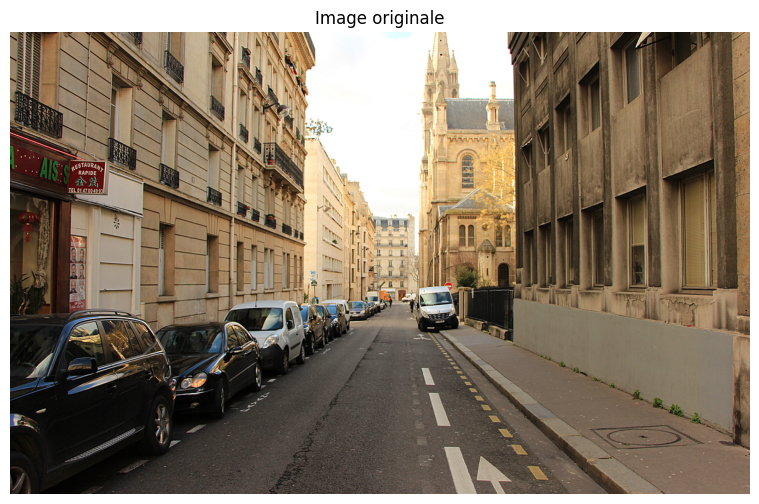

In [9]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title("Image originale")
plt.axis("off")
plt.show()

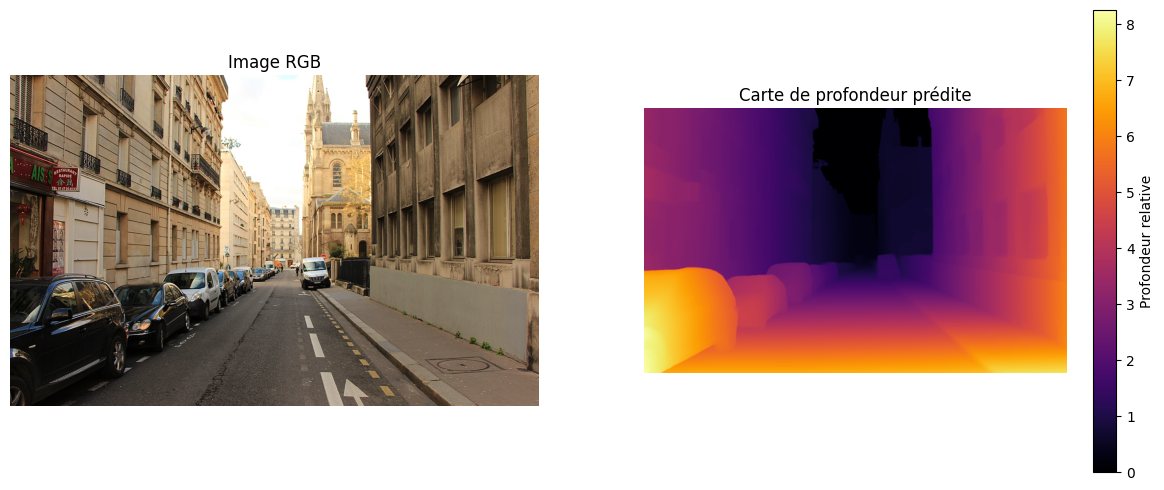

In [10]:
depth = model.infer_image(image)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Image RGB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth, cmap="inferno")
plt.title("Carte de profondeur prédite")
plt.colorbar(label="Profondeur relative")
plt.axis("off")

plt.show()

In [11]:
from google.colab import files

uploaded_video = files.upload()

video_path = next(iter(uploaded_video.keys()))

print("Vidéo chargée :", video_path)

Saving VID_20261118_102513.mp4 to VID_20261118_102513.mp4
Vidéo chargée : VID_20261118_102513.mp4


FPS : 29.991816292001957
Nombre total d'images : 441
Durée : 14.704011111111111 secondes


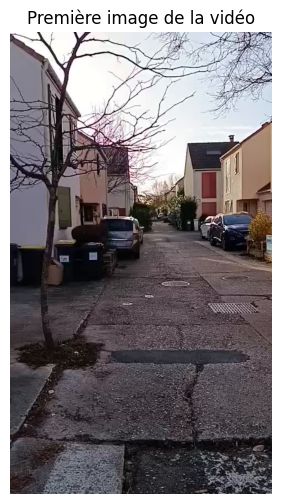

In [12]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("FPS :", fps)
print("Nombre total d'images :", total_frames)
print("Durée :", total_frames / fps, "secondes")

ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.title("Première image de la vidéo")
    plt.axis("off")
    plt.show()

cap.release()

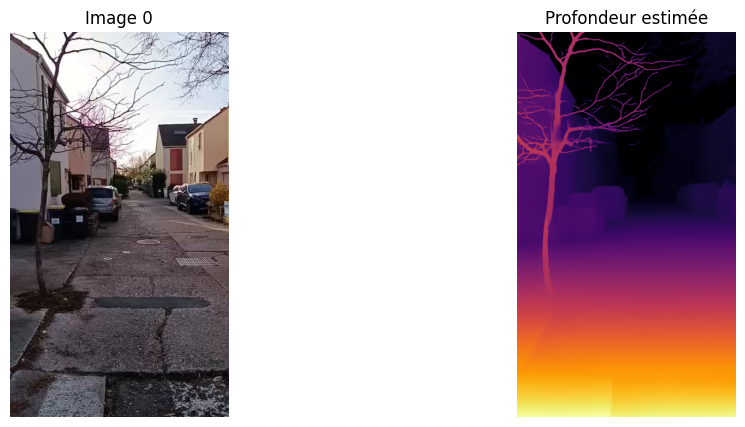

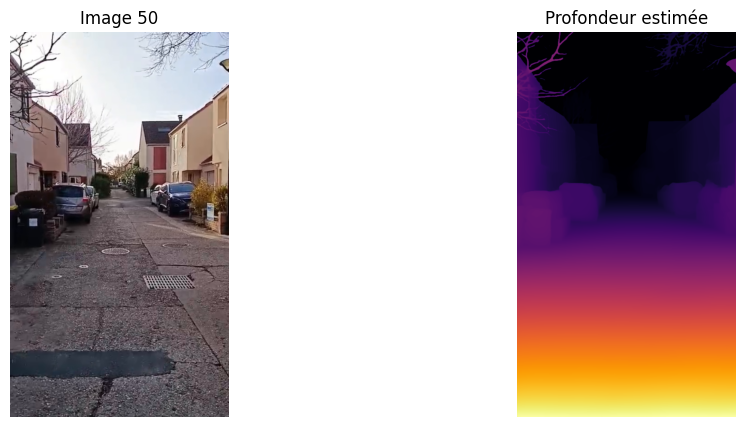

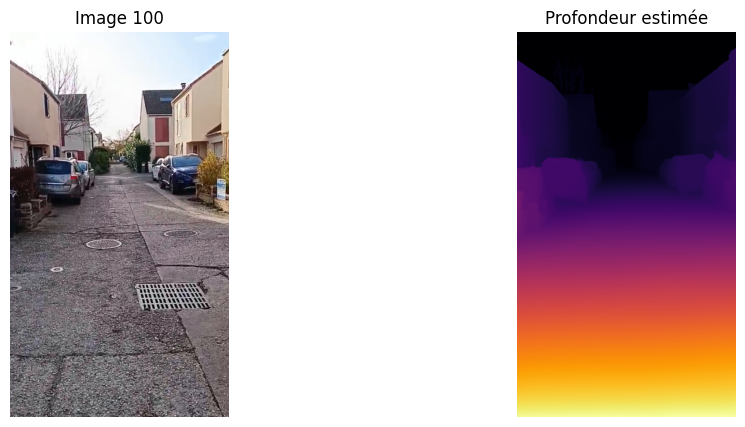

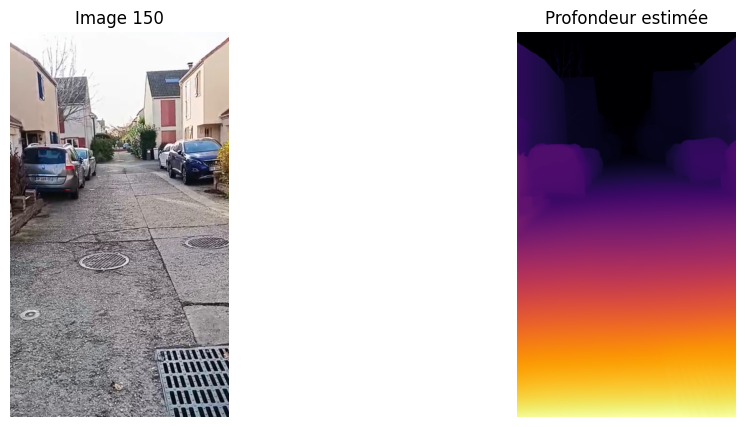

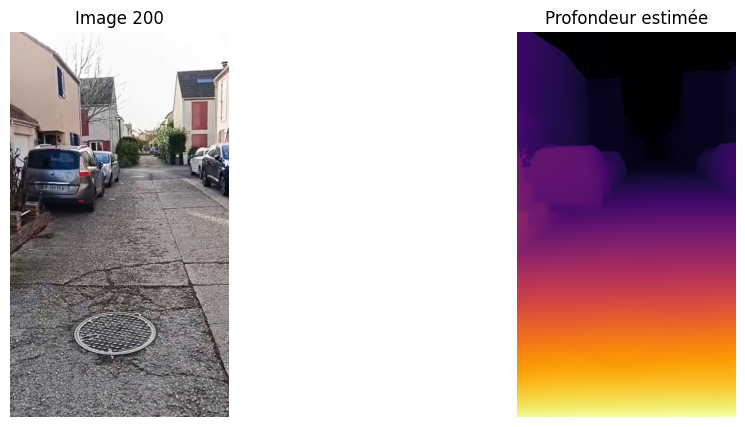

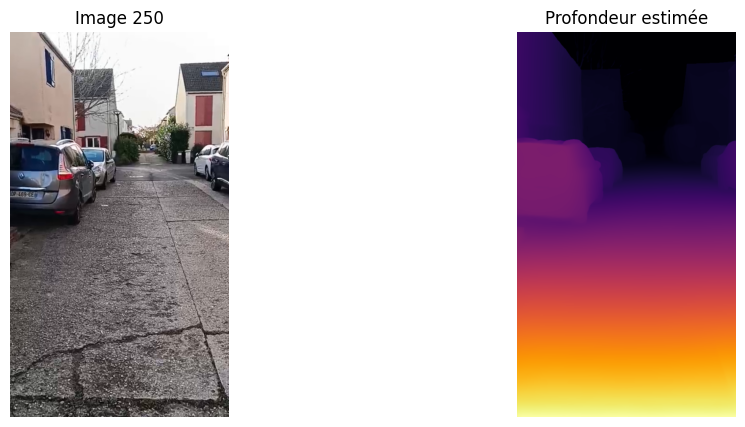

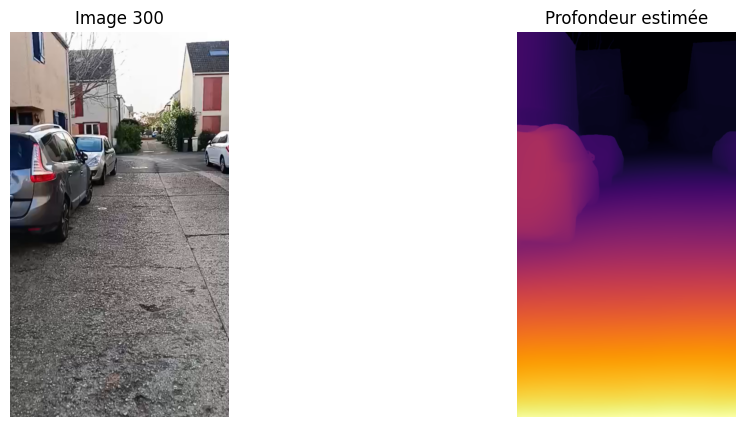

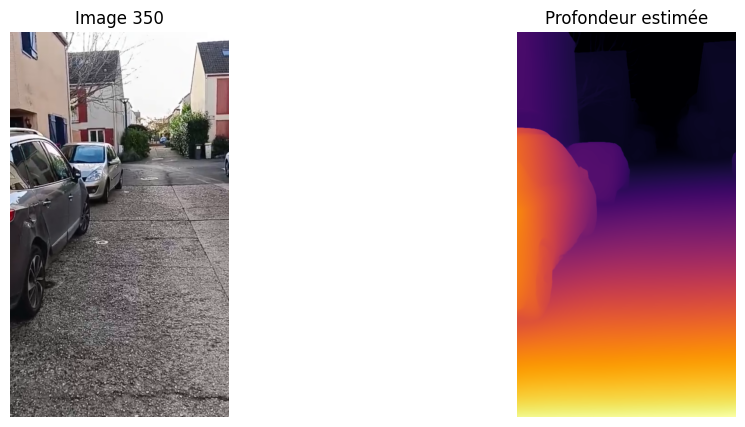

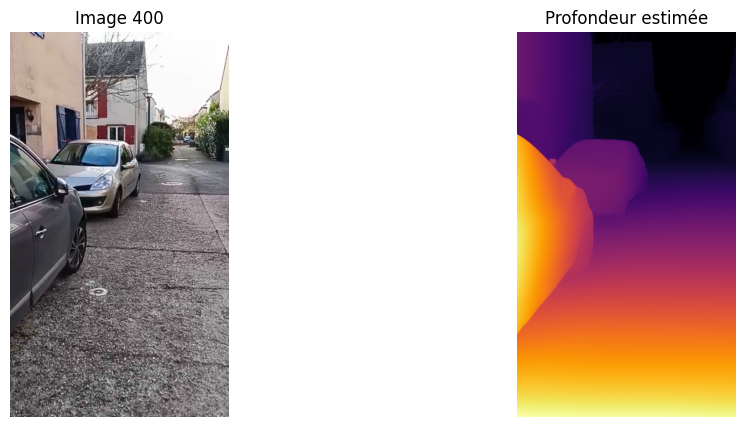

Nombre d'images traitées : 9


In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)

frame_count = 0
processed_count = 0

MAX_FRAMES = 30
FRAME_STEP = 50

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    if frame_count % FRAME_STEP == 0:

        # Réduction de la résolution pour accélérer les tests
        height, width = frame.shape[:2]

        new_width = 640
        new_height = int(height * new_width / width)

        frame = cv2.resize(
            frame,
            (new_width, new_height)
        )

        # Estimation de profondeur
        depth = model.infer_image(frame)

        # Affichage
        frame_rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.imshow(frame_rgb)
        plt.title(f"Image {frame_count}")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(depth, cmap="inferno")
        plt.title("Profondeur estimée")
        plt.axis("off")

        plt.show()

        processed_count += 1

        if processed_count >= MAX_FRAMES:
            break

    frame_count += 1

cap.release()

print("Nombre d'images traitées :", processed_count)

In [16]:
import os

os.makedirs("depth_results", exist_ok=True)

cap = cv2.VideoCapture(video_path)

frame_id = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    if frame_id % 50 == 0:

        depth = model.infer_image(frame)

        depth_normalized = cv2.normalize(
            depth,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        )

        depth_normalized = depth_normalized.astype(np.uint8)

        output_path = f"depth_results/depth_{frame_id:50d}.png"

        cv2.imwrite(output_path, depth_normalized)

    frame_id += 1

cap.release()

print("Cartes de profondeur sauvegardées !")

Cartes de profondeur sauvegardées !
